# Finding POIs

### Package Imports:

In [9]:
import pandas as pd
import numpy as np
import requests
import geopandas as gpd
import re

### Build City Polygon

Import Raleigh polygon from NC DOT. 

In [10]:
# NC NCDOT Municipal Boundaries MapServer (filter to Raleigh, return GeoJSON)
raleigh_url = (
    "https://gis11.services.ncdot.gov/arcgis/rest/services/NCDOT_CityBdy_Poly/MapServer/0/query"
    "?where=MunicipalBoundaryName%3D%27Raleigh%27"
    "&outFields=MunicipalBoundaryName"
    "&returnGeometry=true"
    "&f=geojson"
)

In [11]:
#load city polygon for Raleigh, NC
city = gpd.read_file(raleigh_url)   # GeoJSON response
assert len(city) >= 1, "No Raleigh polygon returned"
city = city.to_crs(2264)            # feet (NAD83 / North Carolina (ftUS))

# In case of multipart polygons, dissolve to one geometry
city_poly = city.dissolve().geometry.iloc[0]

Build one mile buffer ring:

In [12]:
#build buffer ring
one_mile_ft = 5280
city_buffer = gpd.GeoSeries([city_poly]).buffer(one_mile_ft).iloc[0] #buffer city of raleigh by 1 mile
ring_geom = city_buffer.difference(city_poly) #ring is buffer minus city

#convert to geodataframes
city_gdf = gpd.GeoDataFrame(geometry=[city_poly], crs=2264)
ring_gdf = gpd.GeoDataFrame(geometry=[ring_geom], crs=2264)



### Finding POIs using Overpass

In [13]:
# ------------------------------
# A) Build a bbox around the ring (in WGS84) for the Overpass query
# ------------------------------
ring_wgs = ring_gdf.to_crs(4326)                         # lon/lat for Overpass
minx, miny, maxx, maxy = ring_wgs.total_bounds           # bbox: (west, south, east, north)

# Overpass QL: supermarkets in the bbox; 'out center' gives centroids for ways/relations
overpass_url = "https://overpass-api.de/api/interpreter"
query = f"""
[out:json][timeout:60];
(
  node["shop"="supermarket"]({miny},{minx},{maxy},{maxx});
  node["amenity"="supermarket"]({miny},{minx},{maxy},{maxx});

  way["shop"="supermarket"]({miny},{minx},{maxy},{maxx});
  way["amenity"="supermarket"]({miny},{minx},{maxy},{maxx});

  relation["shop"="supermarket"]({miny},{minx},{maxy},{maxx});
  relation["amenity"="supermarket"]({miny},{minx},{maxy},{maxx});
);
out center tags;
"""

resp = requests.post(overpass_url, data={"data": query})
resp.raise_for_status()
data = resp.json()["elements"]

# ------------------------------
# B) Normalize to a GeoDataFrame in WGS84
# ------------------------------
def elem_to_feature(e):
    osm_type = e.get("type")
    osm_id = e.get("id")
    tags = e.get("tags", {})

    # Basic info
    name = tags.get("name")
    brand = tags.get("brand")
    shop = tags.get("shop")
    amenity = tags.get("amenity")

    # Address fields (may be missing!)
    housenumber = tags.get("addr:housenumber")
    street = tags.get("addr:street")
    city = tags.get("addr:city")
    postcode = tags.get("addr:postcode")

    # Representative point
    if osm_type == "node":
        lat, lon = e["lat"], e["lon"]
    else:
        c = e.get("center")
        if not c:
            return None
        lat, lon = c["lat"], c["lon"]

    return {
        "osm_type": osm_type,
        "osm_id": osm_id,
        "name": name,
        "brand": brand,
        "shop": shop,
        "amenity": amenity,
        "lat": lat,
        "lon": lon,
        "addr_housenumber": housenumber,
        "addr_street": street,
        "addr_city": city,
        "addr_postcode": postcode
    }

rows = [elem_to_feature(e) for e in data]
rows = [r for r in rows if r is not None]
osm_df = pd.DataFrame(rows)





Deduplicate results (osm gives duplicates)

In [14]:


# ------------------------------
# 1) Convert to GeoDataFrame
# ------------------------------
osm_gdf = gpd.GeoDataFrame(
    osm_df,
    geometry=gpd.points_from_xy(osm_df["lon"], osm_df["lat"]),
    crs="EPSG:4326"
).to_crs(2264)

# Binary in-ring flag
ring_geom = ring_gdf.geometry.iloc[0]
osm_gdf["in_ring"] = osm_gdf.within(ring_geom).astype(int)

# Optional city flag too
city_geom = city_gdf.geometry.iloc[0]
osm_gdf["in_city"] = osm_gdf.within(city_geom).astype(int)

# ------------------------------
# 2) Clean labels
# ------------------------------
def clean_name(x):
    if pd.isna(x):
        return None
    x = x.lower().strip()
    x = re.sub(r"[^\w\s]", "", x)
    x = re.sub(r"\s+", " ", x)
    return x

osm_gdf["name_clean"] = osm_gdf["name"].apply(clean_name)
osm_gdf["brand_clean"] = osm_gdf["brand"].apply(clean_name)
osm_gdf["label_clean"] = osm_gdf["name_clean"].fillna(osm_gdf["brand_clean"])

# ------------------------------
# 3) Rank rows so better features win
# ------------------------------
type_rank = {"relation": 3, "way": 2, "node": 1}
osm_gdf["type_rank"] = osm_gdf["osm_type"].map(type_rank).fillna(0)
osm_gdf["has_name"] = osm_gdf["name"].notna().astype(int)

# ------------------------------
# 4) Deduplicate within label by proximity
# ------------------------------
def dedupe_group(group, dist_ft=150):
    group = group.sort_values(
        by=["has_name", "type_rank"],
        ascending=[False, False]
    ).copy()

    keep_rows = []
    kept_points = []

    for idx, row in group.iterrows():
        pt = row.geometry

        if not kept_points:
            keep_rows.append(idx)
            kept_points.append(pt)
            continue

        too_close = any(pt.distance(existing) <= dist_ft for existing in kept_points)

        if not too_close:
            keep_rows.append(idx)
            kept_points.append(pt)

    return group.loc[keep_rows]

parts = []
for label, grp in osm_gdf.groupby("label_clean", dropna=False):
    if pd.isna(label):
        # Keep unnamed rows for now; can filter later if needed
        parts.append(grp)
    else:
        parts.append(dedupe_group(grp, dist_ft=150))

pois_dedup = pd.concat(parts, ignore_index=True)

# ------------------------------
# 5) Optional: final column order
# ------------------------------
cols = [
    "osm_type", "osm_id", "name", "brand", "shop", "amenity",
    "lat", "lon", "in_city", "in_ring",
    "name_clean", "brand_clean", "label_clean", "geometry"
]
pois_dedup = pois_dedup[[c for c in cols if c in pois_dedup.columns]]

print(f"Original rows: {len(osm_gdf)}")
print(f"Deduplicated rows: {len(pois_dedup)}")

Original rows: 128
Deduplicated rows: 128


### Plot Locations

C:\Users\tegroton\AppData\Local\Temp\ipykernel_18864\349463654.py:22: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  city_union = city_gdf.geometry.unary_union
C:\Users\tegroton\AppData\Local\Temp\ipykernel_18864\349463654.py:23: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  ring_union = ring_gdf.geometry.unary_union


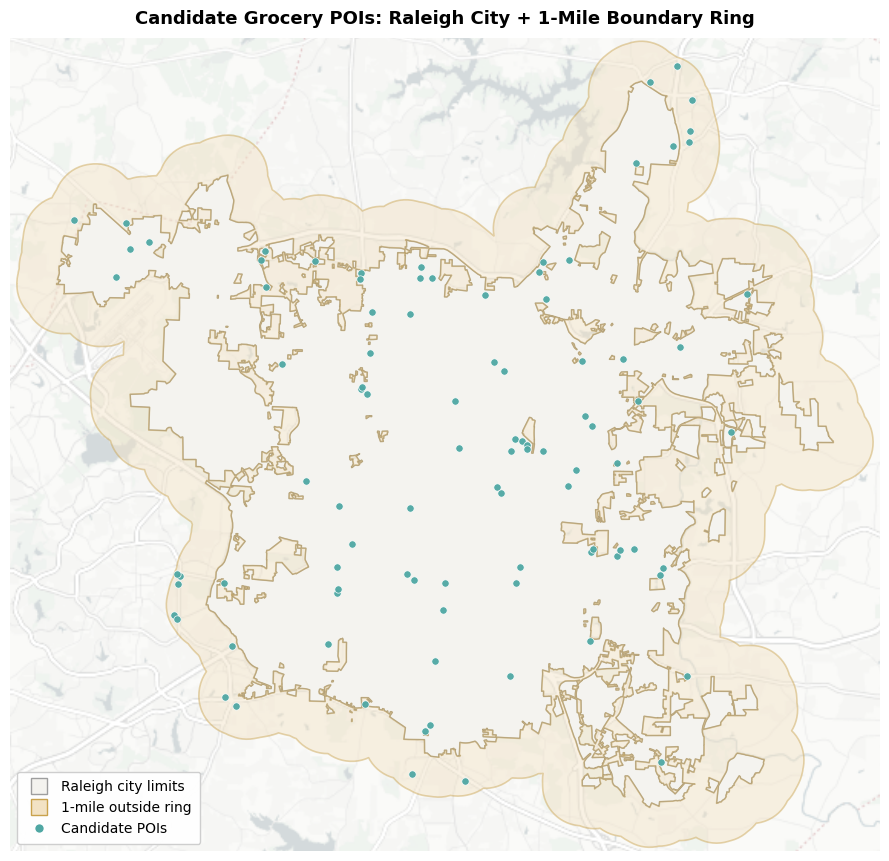

In [15]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import contextily as cx
import geopandas as gpd

# --- sanity: CRS checks ---
assert city_gdf.crs.to_epsg() == 2264
assert ring_gdf.crs.to_epsg() == 2264
assert pois_dedup.crs.to_epsg() == 2264

# --- filter: keep only POIs in city OR ring ---
pois_roi = pois_dedup.loc[
    (pois_dedup["in_city"] == 1) | (pois_dedup["in_ring"] == 1)
].copy()

# optional: drop unnamed artifacts for cleaner first-look map
# pois_roi = pois_roi.loc[pois_roi["label_clean"].notna()].copy()

# -----------------------------
# Ensure ring is OUTSIDE only
# -----------------------------
city_union = city_gdf.geometry.unary_union
ring_union = ring_gdf.geometry.unary_union
ring_outside_geom = ring_union.difference(city_union)
ring_outside = gpd.GeoDataFrame(geometry=[ring_outside_geom], crs=city_gdf.crs)

# -----------------------------
# Color palette
# -----------------------------
city_fill = "#f4f3ef"
city_edge = "#9e9e9e"
ring_fill = "#f2e2c4"
ring_edge = "#c9a24d"
poi_color = "#4fa7a3"

# -----------------------------
# Reproject to Web Mercator
# -----------------------------
city_3857 = city_gdf.to_crs(epsg=3857)
ring_3857 = ring_outside.to_crs(epsg=3857)
pois_3857 = pois_roi.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(9, 9))

# 1) City polygon
city_3857.plot(
    ax=ax,
    facecolor=city_fill,
    edgecolor=city_edge,
    linewidth=0.9,
    alpha=1.0,
    zorder=2
)

# 2) 1-mile outside ring
ring_3857.plot(
    ax=ax,
    facecolor=ring_fill,
    edgecolor=ring_edge,
    linewidth=1.2,
    alpha=0.45,
    zorder=3
)

# 3) POIs
pois_3857.plot(
    ax=ax,
    markersize=28,
    color=poi_color,
    edgecolor="white",
    linewidth=0.5,
    alpha=0.95,
    zorder=4
)

# -----------------------------
# Extent
# -----------------------------
minx, miny, maxx, maxy = city_3857.total_bounds
pad_x = (maxx - minx) * 0.06
pad_y = (maxy - miny) * 0.06
ax.set_xlim(minx - pad_x, maxx + pad_x)
ax.set_ylim(miny - pad_y, maxy + pad_y)

# -----------------------------
# Basemap
# -----------------------------
cx.add_basemap(
    ax,
    source=cx.providers.CartoDB.PositronNoLabels,
    attribution=False,
    zorder=1
)

# -----------------------------
# Cosmetics
# -----------------------------
ax.set_title(
    "Candidate Grocery POIs: Raleigh City + 1-Mile Boundary Ring",
    fontsize=13,
    weight="bold",
    pad=10
)
ax.set_axis_off()
plt.tight_layout()

# -----------------------------
# Legend
# -----------------------------
handles = [
    Line2D([0], [0], marker='s', color='none',
           markerfacecolor=city_fill, markeredgecolor=city_edge,
           markersize=11, label="Raleigh city limits"),
    Line2D([0], [0], marker='s', color='none',
           markerfacecolor=ring_fill, markeredgecolor=ring_edge,
           markersize=11, label="1-mile outside ring"),
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=poi_color, markeredgecolor="white",
           markersize=7, label="Candidate POIs"),
]

ax.legend(
    handles=handles,
    loc="lower left",
    frameon=True,
    fancybox=True,
    framealpha=0.95,
    borderpad=0.6,
    handletextpad=0.6,
    labelspacing=0.5
)

plt.show()